# Process Model Matching on PMMC 2015: Explaining Graph Context

Graph context made the LLM more precise but far less willing to say "match" (notebook 02). This notebook asks which parts of the context caused that, and whether the explanation can be used to fix it.

1. **Attribution.** For each pair, remove one context element at a time (a preceding activity, a following activity, or the actor) and measure the change in P(Yes). This is occlusion attribution: a simple, model-agnostic counterpart to output-attribution methods for graph models.
2. **Hypothesis test.** On true matches that graph context wrongly rejected, check whether the push towards "no match" comes from neighbours that have no counterpart in the other process (different step order).
3. **Faithfulness.** Remove the top-ranked elements and compare with removing random ones.
4. **Repair.** Re-score all candidates with (a) order-robust context that keeps only neighbours with a counterpart on the other side, and (b) selective context, used only when the label-only score is uncertain.

Inputs: `outputs.zip` (notebook 01) and `outputs_graph_context.zip` (notebook 02). Runtime: GPU (a Colab T4 is sufficient).

## Setup

In [1]:
!pip -q install -U transformers accelerate bitsandbytes sentence-transformers networkx scikit-learn pandas tqdm matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os, json, zipfile, random
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import GroupKFold
from sklearn.metrics import precision_recall_fscore_support

SEED = 42; random.seed(SEED); np.random.seed(SEED)
for z in ["outputs.zip", "outputs_graph_context.zip"]:
    assert os.path.exists(z), f"{z} is required (see notebooks 01 and 02)."
    zipfile.ZipFile(z).extractall(".")
OUT_DIR = "outputs_explanations"
os.makedirs(OUT_DIR, exist_ok=True)

pairs = pd.read_csv("outputs_graph_context/pairs_graph_context.csv", dtype={"id1": str, "id2": str})
graphs = {f[:-8]: nx.read_graphml(f"outputs/{f}") for f in os.listdir("outputs") if f.endswith(".graphml")}
cand = pairs[pairs.candidate].copy()
print(f"{len(graphs)} graphs | {len(pairs):,} pairs | {len(cand):,} candidates | {int(pairs.y.sum())} gold matches")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


9 graphs | 20,661 pairs | 4,244 candidates | 178 gold matches


## Context as removable elements

Each side of a pair has up to three preceding activities, up to three following activities and an actor. Every element gets an id so it can be removed on its own.

In [3]:
MAX_N = 3

def elements(model, node, side):
    G = graphs[model]
    els = [{"id": f"{side}:actor", "side": side, "kind": "actor", "text": G.nodes[node].get("actor", "unknown")}]
    for i, p in enumerate(list(G.predecessors(node))[:MAX_N]):
        els.append({"id": f"{side}:before{i}", "side": side, "kind": "before", "text": G.nodes[p].get("label", "")})
    for i, s in enumerate(list(G.successors(node))[:MAX_N]):
        els.append({"id": f"{side}:after{i}", "side": side, "kind": "after", "text": G.nodes[s].get("label", "")})
    return els

def pair_elements(r):
    return elements(r.m1, r.id1, "A") + elements(r.m2, r.id2, "B")

def block(label, els, side, name, full):
    e = [x for x in els if x["side"] == side]
    has = lambda kind: any(x["side"] == side and x["kind"] == kind for x in full)
    actor = next((x["text"] for x in e if x["kind"] == "actor"), "(not shown)")
    before = [x["text"] for x in e if x["kind"] == "before"] or [("(not shown)" if has("before") else "(process start)")]
    after = [x["text"] for x in e if x["kind"] == "after"] or [("(not shown)" if has("after") else "(process end)")]
    return (f"{name}: \"{label}\"\n  performed by: {actor}\n"
            f"  comes after: {'; '.join(before)}\n  followed by: {'; '.join(after)}")

r = cand.iloc[0]
print(block(r.label1, pair_elements(r), "A", "Activity A", pair_elements(r)))

Activity A: "Apply online"
  performed by: Applicant
  comes after: (process start)
  followed by: Send online protocäl


## Model and prompt

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

LLM_NAME = "Qwen/Qwen2.5-7B-Instruct"   # same model as notebooks 01 and 02
bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16, bnb_4bit_quant_type="nf4")
tok = AutoTokenizer.from_pretrained(LLM_NAME); tok.padding_side = "left"
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, quantization_config=bnb, device_map="auto").eval()
YES = [tok.encode(w, add_special_tokens=False)[0] for w in ["Yes", " Yes", "yes"]]
NO  = [tok.encode(w, add_special_tokens=False)[0] for w in ["No", " No", "no"]]

SYSTEM = ("You are an expert in business process management. Two universities describe their "
          "admission processes. Decide if two activities mean the same thing.")

def prompt(r, els):
    full = pair_elements(r)
    user = (f"{block(r.label1, els, 'A', 'Activity A (university 1)', full)}\n\n"
            f"{block(r.label2, els, 'B', 'Activity B (university 2)', full)}\n\n"
            "Check step by step:\n"
            "1. Do the two labels describe the same action on the same object (synonyms count)?\n"
            "2. Is the activity performed by the same kind of actor?\n"
            "3. Do the steps before and after play the same role in both processes?\n"
            "Two activities are the same only if check 1 holds and checks 2-3 do not contradict it.\n"
            "Do A and B describe the same activity? Answer only Yes or No.")
    return tok.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def p_yes(prompts, bs=8):
    out = []
    for i in tqdm(range(0, len(prompts), bs), desc="LLM", leave=False):
        enc = tok(prompts[i:i+bs], return_tensors="pt", padding=True).to(llm.device)
        probs = torch.softmax(llm(**enc).logits[:, -1, :].float(), -1)
        y, n = probs[:, YES].sum(-1), probs[:, NO].sum(-1)
        out.extend((y / (y + n + 1e-9)).cpu().tolist())
    return np.array(out)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

## Attribution

Attribution is run on a focused subset to keep inference affordable: every candidate whose decision changed between the label-only and checklist prompts, every gold match among the candidates, and a random sample of the rest. `MAX_PAIRS` caps the total.

Importance of an element = P(Yes | full context) − P(Yes | context without that element). Positive values push towards "match", negative values towards "no match".

In [5]:
MAX_PAIRS = 400

changed = cand[(cand.llm_label_only >= 0.5) != (cand.llm_struct >= 0.5)]
gold_c = cand[cand.y == 1]
rest = cand.drop(changed.index.union(gold_c.index), errors="ignore")
focus_idx = changed.index.union(gold_c.index)
extra = rest.sample(min(len(rest), max(0, MAX_PAIRS - len(focus_idx))), random_state=SEED).index
sub = cand.loc[focus_idx.union(extra)].copy()
if len(sub) > MAX_PAIRS:
    sub = sub.sample(MAX_PAIRS, random_state=SEED)
print(f"{len(sub)} pairs: {len(changed)} changed decisions, {len(gold_c)} gold matches among candidates")

jobs, rows = [], []
for r in sub.itertuples():
    els = pair_elements(r)
    jobs.append(prompt(r, els)); rows.append((r.Index, None, None))
    for e in els:
        jobs.append(prompt(r, [x for x in els if x["id"] != e["id"]])); rows.append((r.Index, e, els))
scores = p_yes(jobs)

full = {i: s for (i, e, _), s in zip(rows, scores) if e is None}
attr = pd.DataFrame([{"pair": i, "element": e["id"], "side": e["side"], "kind": e["kind"], "text": e["text"],
                      "p_full": full[i], "p_without": s, "importance": full[i] - s}
                     for (i, e, _), s in zip(rows, scores) if e is not None])
attr.to_csv(f"{OUT_DIR}/attributions.csv", index=False)
print(f"{len(jobs):,} prompts scored | {len(attr):,} element attributions")
attr.groupby("kind").importance.describe()[["count", "mean", "std", "min", "max"]]

400 pairs: 159 changed decisions, 146 gold matches among candidates


LLM:   0%|          | 0/389 [00:00<?, ?it/s]

3,111 prompts scored | 2,711 element attributions


,count,mean,std,min,max
kind,,,,,
actor,800.0,0.036533,0.197873,-0.977023,0.998498
after,888.0,-0.013025,0.150369,-0.985757,0.996397
before,1023.0,0.003648,0.200021,-0.999765,0.999934


## Do unmatched neighbours cause the lost matches?

A neighbour is *aligned* if a similar activity appears in the other side's neighbourhood (cosine similarity of label embeddings ≥ `ALIGN_T`), and *unaligned* otherwise. If differing step order is the problem, unaligned neighbours should carry the negative attribution on true matches that graph context rejected.

In [6]:
from sentence_transformers import SentenceTransformer
emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda" if torch.cuda.is_available() else "cpu")
ALIGN_T = 0.5

def aligned_flags(els):
    nb = [e for e in els if e["kind"] != "actor"]
    if not nb:
        return {}
    v = emb.encode([e["text"] for e in nb], normalize_embeddings=True)
    flags = {}
    for i, e in enumerate(nb):
        other = [j for j, o in enumerate(nb) if o["side"] != e["side"]]
        flags[e["id"]] = bool(other) and float(np.max(v[other] @ v[i])) >= ALIGN_T
    return flags

flag_map = {}
for r in sub.itertuples():
    for k, v in aligned_flags(pair_elements(r)).items():
        flag_map[(r.Index, k)] = v
attr["aligned"] = [flag_map.get((p, e)) for p, e in zip(attr.pair, attr.element)]

lost = sub[(sub.y == 1) & (sub.llm_label_only >= 0.5) & (sub.llm_struct < 0.5)].index
nb = attr[attr.kind != "actor"].copy()
nb["group"] = np.where(nb.pair.isin(lost), "true matches lost to context", "other pairs")
summary = (nb.groupby(["group", "aligned"]).importance
             .agg(n="count", mean="mean", share_negative=lambda s: (s < 0).mean()).round(3))
print(f"{len(lost)} true matches were lost when graph context was added")
summary

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

64 true matches were lost when graph context was added


n   mean  share_negative
group                        aligned                             
other pairs                  False    1166 -0.000           0.557
                             True      456  0.055           0.399
true matches lost to context False     182 -0.110           0.560
                             True      107 -0.117           0.523

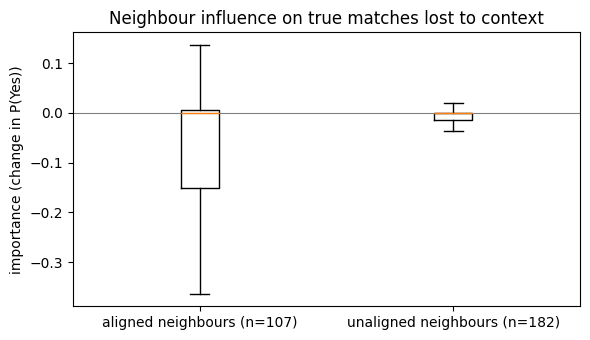

In [7]:
data = [nb[(nb.group == "true matches lost to context") & (nb.aligned == a)].importance.values for a in [True, False]]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([d if len(d) else np.array([np.nan]) for d in data], showfliers=False)
ax.set_xticks([1, 2], [f"aligned neighbours (n={len(data[0])})", f"unaligned neighbours (n={len(data[1])})"])
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("importance (change in P(Yes))")
ax.set_title("Neighbour influence on true matches lost to context")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/neighbour_importance.png", dpi=150); plt.show()

## Faithfulness check

If the attributions are faithful, removing the top-k elements that support the model's decision should change P(Yes) more than removing k random elements.

In [8]:
def deletion_test(k, trials=3):
    jobs_top, jobs_rand, meta = [], [], []
    for r in sub.itertuples():
        els = pair_elements(r)
        a = attr[attr.pair == r.Index].set_index("element").importance
        if len(els) <= k:
            continue
        sign = 1 if full[r.Index] >= 0.5 else -1          # elements supporting the current decision
        top = list((a * sign).sort_values(ascending=False).index[:k])
        jobs_top.append(prompt(r, [e for e in els if e["id"] not in top]))
        for _ in range(trials):
            drop = set(random.sample([e["id"] for e in els], k))
            jobs_rand.append(prompt(r, [e for e in els if e["id"] not in drop]))
        meta.append(r.Index)
    pt, pr = p_yes(jobs_top), p_yes(jobs_rand).reshape(-1, trials).mean(1)
    base = np.array([full[i] for i in meta])
    return {"k": k, "pairs": len(meta),
            "mean |change|, top-k": round(float(np.abs(base - pt).mean()), 3),
            "mean |change|, random": round(float(np.abs(base - pr).mean()), 3),
            "decision flips, top-k": round(float(((base >= 0.5) != (pt >= 0.5)).mean()), 3),
            "decision flips, random": round(float(((base >= 0.5) != (pr >= 0.5)).mean()), 3)}

faith = pd.DataFrame([deletion_test(1), deletion_test(2)])
faith.to_csv(f"{OUT_DIR}/faithfulness.csv", index=False)
faith

LLM:   0%|          | 0/50 [00:00<?, ?it/s]

LLM:   0%|          | 0/150 [00:00<?, ?it/s]

LLM:   0%|          | 0/50 [00:00<?, ?it/s]

LLM:   0%|          | 0/150 [00:00<?, ?it/s]

,k,pairs,"mean |change|, top-k","mean |change|, random","decision flips, top-k","decision flips, random"
0,1,400,0.164,0.047,0.175,0.043
1,2,400,0.219,0.074,0.233,0.058


## Repair

Two ways to keep the precision gain without losing so much recall. Neither uses gold labels.

* **Order-robust context:** keep the actor and only those neighbours that have a similar counterpart on the other side.
* **Selective context:** use the checklist-with-context score only when the label-only score is uncertain (between `LOW` and `HIGH`); otherwise keep the label-only score.

In [9]:
def robust_elements(r):
    els = pair_elements(r)
    flags = aligned_flags(els)
    return [e for e in els if e["kind"] == "actor" or flags.get(e["id"], False)]

cand["llm_robust"] = p_yes([prompt(r, robust_elements(r)) for r in cand.itertuples()])

LOW, HIGH = 0.3, 0.7
uncertain = cand.llm_label_only.between(LOW, HIGH)
cand["llm_selective"] = np.where(uncertain, cand.llm_struct, cand.llm_label_only)
cand["llm_selective_robust"] = np.where(uncertain, cand.llm_robust, cand.llm_label_only)
for c in ["llm_robust", "llm_selective", "llm_selective_robust"]:
    pairs[c] = 0.0
    pairs.loc[cand.index, c] = cand[c]
print(f"{int(uncertain.sum())} of {len(cand)} candidates fall in the uncertain band")

LLM:   0%|          | 0/531 [00:00<?, ?it/s]

22 of 4244 candidates fall in the uncertain band


In [10]:
def prf(y, p):
    P, R, F, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    return round(P, 3), round(R, 3), round(F, 3)

def best_threshold(y, s):
    return max(np.linspace(0.05, 0.95, 91), key=lambda t: prf(y, (s >= t).astype(int))[2])

gkf = GroupKFold(n_splits=6)
def tuned_pred(s):
    pred = np.zeros(len(pairs), dtype=int)
    for tr, te in gkf.split(pairs, pairs.y, pairs.group):
        pred[te] = (s[te] >= best_threshold(pairs.y.values[tr], s[tr])).astype(int)
    return pred

y = pairs.y.values
rows = []
for name, col in [("LLM, labels only", "llm_label_only"),
                  ("LLM + full context + checklist", "llm_struct"),
                  ("LLM + order-robust context", "llm_robust"),
                  ("Selective context", "llm_selective"),
                  ("Selective + order-robust context", "llm_selective_robust")]:
    s = pairs[col].values
    rows.append((name, "0.5", *prf(y, (s >= 0.5).astype(int))))
    rows.append((name, "tuned", *prf(y, tuned_pred(s))))
results = pd.DataFrame(rows, columns=["Method", "Threshold", "Precision", "Recall", "F1"])
results.to_csv(f"{OUT_DIR}/results_repair.csv", index=False)
results

,Method,Threshold,Precision,Recall,F1
0,"LLM, labels only",0.5,0.529,0.663,0.589
1,"LLM, labels only",tuned,0.536,0.635,0.581
2,LLM + full context + checklist,0.5,0.764,0.309,0.440
3,LLM + full context + checklist,tuned,0.733,0.371,0.493
4,LLM + order-robust context,0.5,0.705,0.483,0.573
5,LLM + order-robust context,tuned,0.636,0.500,0.560
6,Selective context,0.5,0.551,0.640,0.592
7,Selective context,tuned,0.531,0.635,0.578
8,Selective + order-robust context,0.5,0.553,0.646,0.596
9,Selective + order-robust context,tuned,0.533,0.640,0.582


## Examples

Pairs where order-robust context recovered a true match that full context had rejected, with the most influential elements.

In [11]:
recovered = cand[(cand.y == 1) & (cand.llm_struct < 0.5) & (cand.llm_robust >= 0.5)]
print(f"{len(recovered)} true matches recovered by order-robust context\n")
for r in recovered.head(3).itertuples():
    print(f"A: {r.label1}  |  B: {r.label2}")
    print(f"P(Yes): labels only {r.llm_label_only:.2f}, full context {r.llm_struct:.2f}, order-robust {r.llm_robust:.2f}")
    a = attr[attr.pair == r.Index].sort_values("importance")
    for x in a.head(3).itertuples():
        print(f"   pushes towards no match ({x.importance:+.2f}): {x.side} {x.kind} '{x.text}'")
    print("-" * 70)

31 true matches recovered by order-robust context

A: Send letter of rejection  |  B: Send letter of rejection
P(Yes): labels only 1.00, full context 0.00, order-robust 1.00
   pushes towards no match (-0.99): B before 'Evaluate'
   pushes towards no match (-0.03): A before 'Rank students according to GPA and the test results'
   pushes towards no match (-0.03): B actor 'Goethe University Frankfurt'
----------------------------------------------------------------------
A: Send letter of acceptance  |  B: Send letter of acceptance
P(Yes): labels only 1.00, full context 0.04, order-robust 1.00
   pushes towards no match (-0.98): B before 'Evaluate'
   pushes towards no match (-0.13): B actor 'Goethe University Frankfurt'
   pushes towards no match (-0.04): A before 'Rank students according to GPA and the test results'
----------------------------------------------------------------------
A: Send letter of rejection  |  B: Send letter of rejection
P(Yes): labels only 1.00, full context 0.

## Outputs

In [12]:
pairs.to_csv(f"{OUT_DIR}/pairs_explanations.csv", index=False)
!zip -qr outputs_explanations.zip {OUT_DIR}
print("Saved outputs_explanations/ and outputs_explanations.zip")
results

Saved outputs_explanations/ and outputs_explanations.zip


,Method,Threshold,Precision,Recall,F1
0,"LLM, labels only",0.5,0.529,0.663,0.589
1,"LLM, labels only",tuned,0.536,0.635,0.581
2,LLM + full context + checklist,0.5,0.764,0.309,0.440
3,LLM + full context + checklist,tuned,0.733,0.371,0.493
4,LLM + order-robust context,0.5,0.705,0.483,0.573
5,LLM + order-robust context,tuned,0.636,0.500,0.560
6,Selective context,0.5,0.551,0.640,0.592
7,Selective context,tuned,0.531,0.635,0.578
8,Selective + order-robust context,0.5,0.553,0.646,0.596
9,Selective + order-robust context,tuned,0.533,0.640,0.582
